In [1]:
import sys
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO))

import corpora
from evaluation import ablation, matching
from evaluation import scoring as report
from schemaoracle import cache, inventory

RESULTS = REPO / "results"
RUNS = RESULTS / "runs"
FIGDIR = REPO / "figures"

CORPUS = "gdc"
RETRIEVER_CFG = {"embedding_model": "Qwen/Qwen3-Embedding-4B",
                 "encoding_mode": "header_values_xml",
                 "sampling_mode": "priority_sampling", "sampling_size": 10, "seed": 0}
RETRIEVER_B_CFG = {"embedding_model": "vida-nyu/magneto-schema-retriever-gdc",
                   "encoding_mode": "header_values_verbose",
                   "sampling_mode": "priority_sampling", "sampling_size": 10, "seed": 0}
ORDERS = ["qwen", "magneto"]
MODELS = {#"deepseek-v4-flash-cloud": ("DeepSeek V4 Flash", "#2563eb"),
          "deepseek-v4.1-flash-cloud": ("DeepSeek V4.1 Flash", "#56b4e9"),
          #"deepseek-v4-pro-cloud": ("DeepSeek V4 Pro", "#d55e00"),
          #"jev-1.13": ("Jev 1.13", "#cc79a7"),
          "claude-sonnet-5": ("Sonnet 5", "#0f766e")}
ARMS = ["rerank", "gated", "paged"]
MARKER = {"rerank": "D", "gated": "P", "paged": "o"}
FILTERS = ["", "mutual", "zero", "mutual-zero"]
VARIANTS = ["tgt-match-retriever__retry3", "tgt-match-retriever"]
TOP_K, WINDOW, TAU = 20, 20, 0.0

C_INK, C_MUTE = "#1e293b", "#94a3b8"
W1, W2 = 3.33, 7.0
mpl.rcParams.update({
    "figure.dpi": 130, "savefig.dpi": 400, "savefig.bbox": "tight",
    "font.family": "serif", "font.serif": ["DejaVu Serif"], "font.size": 7.5,
    "axes.titlesize": 7.5, "axes.labelsize": 7.5, "legend.fontsize": 7,
    "xtick.labelsize": 7, "ytick.labelsize": 7,
    "text.color": C_INK, "xtick.color": C_INK, "ytick.color": C_INK,
    "axes.edgecolor": C_INK, "axes.labelcolor": C_INK,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.16, "grid.linewidth": 0.4,
    "legend.frameon": False, "lines.linewidth": 1.1, "lines.markersize": 4.0,
    "pdf.fonttype": 42, "ps.fonttype": 42,
})


def save(fig, name):
    FIGDIR.mkdir(exist_ok=True)
    for ext in ("pdf", "png"):
        fig.savefig(FIGDIR / f"{name}.{ext}")


def caption(text):
    print(f"DRAFT CAPTION: {text}")


def model_handles():
    return [mpl.patches.Patch(color=c, label=n) for n, c in MODELS.values()]

In [2]:
PAIRS = corpora.load(CORPUS)
NAMES = [cache.fs_safe(p["name"]) for p in PAIRS]
N_SRC = sum(p["source_df"].shape[1] for p in PAIRS)
N_GOLD_PAIRS = sum(len(p["ground_truth"]) for p in PAIRS)

CORPUS_LABEL = {"gdc": "GDC-SM", "valentine/chembl": "ChEMBL",
                "valentine/opendata": "OpenData", "valentine/tpc-di": "TPC-DI",
                "valentine/magellan": "Magellan",
                "valentine/wikidata": "Wikidata"}
CORPORA = {name: corpora.load(name) for name in CORPUS_LABEL}

C:\Users\muril\SchemaOracle\corpora\registry.py:129: UserWarning: valentine/wikidata: ground truth names 2 source column(s) that are not in the source frame (Wikidata/Musicians/Musicians_unionable: givenName; Wikidata/Musicians/Musicians_viewunion: givenName). No matcher can reach them, and they are counted by MRR but not by the precision, so the two use different denominators.
  _warn_unreachable_gold(name, out)


In [3]:
def gold_ranks_for(cfg, pairs, corpus=CORPUS):
    payload = ablation.load_config(RESULTS, corpus, cfg)
    if payload is None:
        return np.zeros(0, dtype=float)
    rows = ablation.gold_rank_rows(payload, pairs)
    return np.array([r["rank"] if r["rank"] else np.inf for r in rows],
                    dtype=float)


def cdf(ranks, grid):
    return np.array([(ranks <= k).mean() for k in grid])


ABL = pd.read_csv(RESULTS / f"ablation_summary_{CORPUS.replace('/', '-')}.csv")
HIGHLIGHTED = {RETRIEVER_CFG["embedding_model"],
               RETRIEVER_B_CFG["embedding_model"]}
BEST_CFG = (ABL[~ABL["embedding_model"].isin(HIGHLIGHTED)]
            .sort_values("mrr", ascending=False)
            .groupby("embedding_model").head(1))

KGRID = np.unique(np.round(np.geomspace(1, 736, 90)).astype(int))
curves = []
for row in BEST_CFG.to_dict("records"):
    cfg = {k: row[k] for k in ablation.CONFIG_FIELDS}
    cfg["sampling_size"], cfg["seed"] = int(cfg["sampling_size"]), int(cfg["seed"])
    ranks = gold_ranks_for(cfg, PAIRS)
    if not len(ranks):
        continue
    curves.append({"encoder": str(row["embedding_model"]).split("/")[-1],
                   "config": ablation.label(cfg), "role": "other",
                   "n_gold": len(ranks), "recall@1": float((ranks <= 1).mean()),
                   "recall@20": float((ranks <= 20).mean()),
                   "_ranks": ranks})

for role, cfg in (("ours", RETRIEVER_CFG), ("magneto", RETRIEVER_B_CFG)):
    ranks = gold_ranks_for(cfg, PAIRS)
    curves.append({"encoder": str(cfg["embedding_model"]).split("/")[-1],
                   "config": ablation.label(cfg), "role": role,
                   "n_gold": len(ranks), "recall@1": float((ranks <= 1).mean()),
                   "recall@20": float((ranks <= 20).mean()),
                   "_ranks": ranks})

FIG1A = pd.DataFrame([{k: v for k, v in c.items() if not k.startswith("_")}
                      for c in curves])

FIG1B = []
for name, pairs in CORPORA.items():
    n_src = sum(p["source_df"].shape[1] for p in pairs)
    with_gold = sum(len({s for s, _ in p["ground_truth"]}) for p in pairs)
    FIG1B.append({"corpus": CORPUS_LABEL[name], "pairs": len(pairs),
                  "source_columns": n_src, "with_gold": with_gold,
                  "no_gold": n_src - with_gold,
                  "share_no_gold": (n_src - with_gold) / n_src if n_src else np.nan})
FIG1B = pd.DataFrame(FIG1B).sort_values("share_no_gold", ascending=False)

In [4]:
FIG1B

,corpus,pairs,source_columns,with_gold,no_gold,share_no_gold
0,GDC-SM,10,569,165,404,0.710018
2,OpenData,180,6876,4572,2304,0.335079
5,Wikidata,4,60,40,20,0.333333
1,ChEMBL,180,3060,2052,1008,0.329412
3,TPC-DI,180,2916,1980,936,0.320988
4,Magellan,7,41,41,0,0.000000


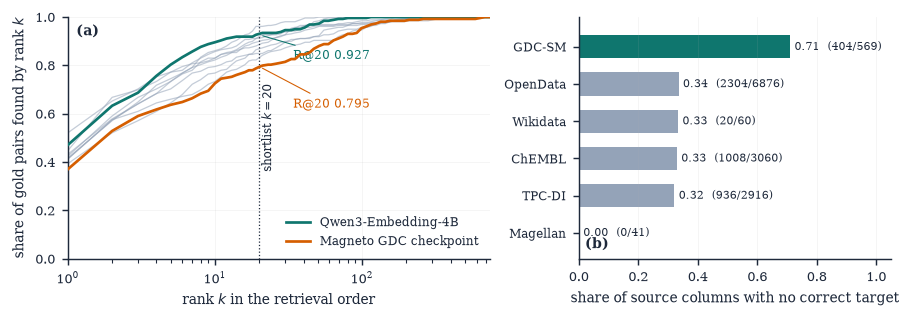

DRAFT CAPTION: (a) Cumulative share of the 259 GDC-SM gold pairs found by rank $k$, log scale, over all 10 studies pooled. Qwen3-Embedding-4B under the header_values_xml serialization reaches 0.927 by $k=20$; Magneto's fine-tuned GDC checkpoint under our header_values_verbose serialization reaches 0.795. Grey: the other 8 cached encoders, each at its own best configuration by MRR. (b) Share of source columns with no correct target, per corpus; GDC-SM is 404 of 569 (71.0%).


In [5]:
fig, (axa, axb) = plt.subplots(1, 2, figsize=(W2, 2.5),
                               gridspec_kw={"width_ratios": [1.35, 1]})

for c in curves:
    if c["role"] != "other":
        continue
    axa.plot(KGRID, cdf(c["_ranks"], KGRID), color=C_MUTE, lw=0.7,
             alpha=0.55, zorder=1)
for c in curves:
    if c["role"] == "other":
        continue
    style = ("#0f766e", "Qwen3-Embedding-4B") if c["role"] == "ours" \
        else ("#d55e00", "Magneto GDC checkpoint")
    axa.plot(KGRID, cdf(c["_ranks"], KGRID), color=style[0], lw=1.5,
             label=style[1], zorder=3)
    r20 = c["recall@20"]
    axa.annotate(f"R@20 {r20:.3f}", xy=(20, r20),
                 xytext=(34, r20 - (0.10 if c["role"] == "ours" else 0.17)),
                 fontsize=6.6, color=style[0],
                 arrowprops=dict(arrowstyle="-", color=style[0], lw=0.6))

axa.axvline(20, color=C_INK, lw=0.7, ls=":", zorder=2)
axa.text(21, 0.36, "shortlist $k=20$", fontsize=6.4, color=C_INK,
         rotation=90, va="bottom")
axa.set_xscale("log")
axa.set_xlim(1, 736)
axa.set_ylim(0, 1.0)
axa.set_xlabel("rank $k$ in the retrieval order")
axa.set_ylabel("share of gold pairs found by rank $k$")
axa.legend(loc="lower right", fontsize=6.6)
axa.text(0.02, 0.97, "(a)", transform=axa.transAxes, fontsize=8,
         va="top", fontweight="bold")

order = FIG1B.sort_values("share_no_gold")
ypos = np.arange(len(order))
axb.barh(ypos, order["share_no_gold"], color=C_MUTE, height=0.62)
gdc = order["corpus"] == CORPUS_LABEL[CORPUS]
axb.barh(ypos[gdc.to_numpy()], order.loc[gdc, "share_no_gold"],
         color="#0f766e", height=0.62)
for y, r in zip(ypos, order.to_dict("records")):
    axb.text(r["share_no_gold"] + 0.015, y,
             f"{r['share_no_gold']:.2f}  ({r['no_gold']}/{r['source_columns']})",
             va="center", fontsize=6.2, color=C_INK)
axb.set_yticks(ypos, order["corpus"], fontsize=6.8)
axb.set_xlim(0, 1.05)
axb.set_ylim(-0.7, len(order) - 0.2)
axb.set_xlabel("share of source columns with no correct target")
axb.grid(axis="y", visible=False)
axb.text(0.02, 0.03, "(b)", transform=axb.transAxes, fontsize=8,
         va="bottom", fontweight="bold")

fig.tight_layout()
save(fig, "fig1_where_the_gold_is")
plt.show()

ours = FIG1A[FIG1A["role"] == "ours"].iloc[0]
mag = FIG1A[FIG1A["role"] == "magneto"].iloc[0]
gdc_row = FIG1B[FIG1B["corpus"] == CORPUS_LABEL[CORPUS]].iloc[0]
caption(
    f"(a) Cumulative share of the {N_GOLD_PAIRS} GDC-SM gold pairs found by rank $k$, "
    f"log scale, over all {len(PAIRS)} studies pooled. "
    f"{ours['encoder']} under the {RETRIEVER_CFG['encoding_mode']} serialization "
    f"reaches {ours['recall@20']:.3f} by $k=20$; Magneto's fine-tuned GDC "
    f"checkpoint under our {RETRIEVER_B_CFG['encoding_mode']} serialization "
    f"reaches {mag['recall@20']:.3f}. Grey: the other "
    f"{int((FIG1A['role'] == 'other').sum())} cached encoders, each at its own "
    f"best configuration by MRR. "
    f"(b) Share of source columns with no correct target, per corpus; GDC-SM is "
    f"{gdc_row['no_gold']} of {gdc_row['source_columns']} "
    f"({gdc_row['share_no_gold']:.1%}).")

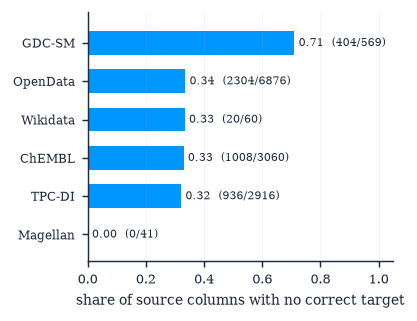

In [6]:
# Adjusted figsize for a single plot (you can change the width as needed)
fig, ax = plt.subplots(figsize=(W2 * 0.45, 2.5)) 

order = FIG1B.sort_values("share_no_gold")
ypos = np.arange(len(order))

# Plot all bars
ax.barh(ypos, order["share_no_gold"], color="#0096FF", height=0.62)

# Highlight the GDC bar
gdc = order["corpus"] == CORPUS_LABEL[CORPUS]
#ax.barh(ypos[gdc.to_numpy()], order.loc[gdc, "share_no_gold"],
#        color="#0f766e", height=0.62)

# Add text annotations next to the bars
for y, r in zip(ypos, order.to_dict("records")):
    ax.text(r["share_no_gold"] + 0.015, y,
            f"{r['share_no_gold']:.2f}  ({r['no_gold']}/{r['source_columns']})",
            va="center", fontsize=6.2, color=C_INK)

# Formatting
ax.set_yticks(ypos, order["corpus"], fontsize=6.8)
ax.set_xlim(0, 1.05)
ax.set_ylim(-0.7, len(order) - 0.2)
ax.set_xlabel("share of source columns with no correct target")
ax.grid(axis="y", visible=False)


fig.tight_layout()
save(fig, "fig1_share_correct_target") # Update filename if desired
plt.show()

# Retained the relevant data extraction for the remaining figure
gdc_row = FIG1B[FIG1B["corpus"] == CORPUS_LABEL[CORPUS]].iloc[0]

In [7]:
def tagged(frame):
    return frame.assign(model=frame["arm"].str.split("__").str[0],
                        variant=frame["arm"].str.split("__").str[1:].str.join("__"))


INV = tagged(inventory.scan(RUNS, corpus=CORPUS, kinds=tuple(ARMS)))
INV = INV[INV["pair"].isin(NAMES) & (INV["rep"] == 1)
          & INV["retriever"].isin(ORDERS) & INV["model"].isin(MODELS)
          & INV["variant"].isin(VARIANTS) & INV["prune"].isin(FILTERS)
          & ((INV["kind"] != "paged") & (INV["top_k"] == TOP_K)
             | (INV["kind"] == "paged") & (INV["window"] == WINDOW)
             & (INV["threshold"] == TAU))]
OK = tagged(inventory.check(INV, verbose=False))

RUNS_OF, rows = {}, []
for ret in ORDERS:
    for arm in ARMS:
        for m in MODELS:
            for f in FILTERS:
                cell = OK[(OK["retriever"] == ret) & (OK["kind"] == arm)
                          & (OK["model"] == m) & (OK["prune"] == f)]
                for v in VARIANTS:
                    runs = cell[cell["variant"] == v]
                    if (set(runs["pair"]) == set(NAMES)
                            and runs["n_columns"].sum() == N_SRC):
                        RUNS_OF[(ret, arm, m, f)] = runs
                        s = report.score(runs, PAIRS, results=RUNS,
                                         corpus=CORPUS, kind=arm).iloc[0]
                        rows.append({**s, "retriever": ret, "kind": arm,
                                     "model": m, "filter": f})
                        break
                else:
                    print(f"not whole: {ret} / {arm} / {MODELS[m][0]} / "
                          f"{f or 'none'}")
SCORED = pd.DataFrame(rows)

RET, DEEP = {}, {}
for ret in ORDERS:
    order, gt = report.retrieval_rankings(PAIRS, results=RUNS, corpus=CORPUS,
                                          retriever=ret)
    RET[ret] = report.metrics(order, gt, {c: True for c in order})
    DEEP[ret] = {(s, t) for s, t, _ in matching.gold_beyond_k(order, gt, TOP_K)}
N_GOLD_COLS = RET["qwen"]["n_gold_columns"]
N_FREE = N_SRC - N_GOLD_COLS


def row(ret, arm, m, f=""):
    r = SCORED[(SCORED["retriever"] == ret) & (SCORED["kind"] == arm)
               & (SCORED["model"] == m) & (SCORED["filter"] == f)]
    return r.iloc[0] if len(r) else None

not whole: magneto / rerank / DeepSeek V4.1 Flash / none
not whole: magneto / rerank / DeepSeek V4.1 Flash / mutual
not whole: magneto / rerank / DeepSeek V4.1 Flash / zero
not whole: magneto / rerank / DeepSeek V4.1 Flash / mutual-zero
not whole: magneto / rerank / Sonnet 5 / mutual
not whole: magneto / rerank / Sonnet 5 / zero
not whole: magneto / rerank / Sonnet 5 / mutual-zero
not whole: magneto / gated / DeepSeek V4.1 Flash / none
not whole: magneto / gated / Sonnet 5 / mutual
not whole: magneto / gated / Sonnet 5 / zero
not whole: magneto / gated / Sonnet 5 / mutual-zero
not whole: magneto / paged / Sonnet 5 / mutual
not whole: magneto / paged / Sonnet 5 / zero
not whole: magneto / paged / Sonnet 5 / mutual-zero


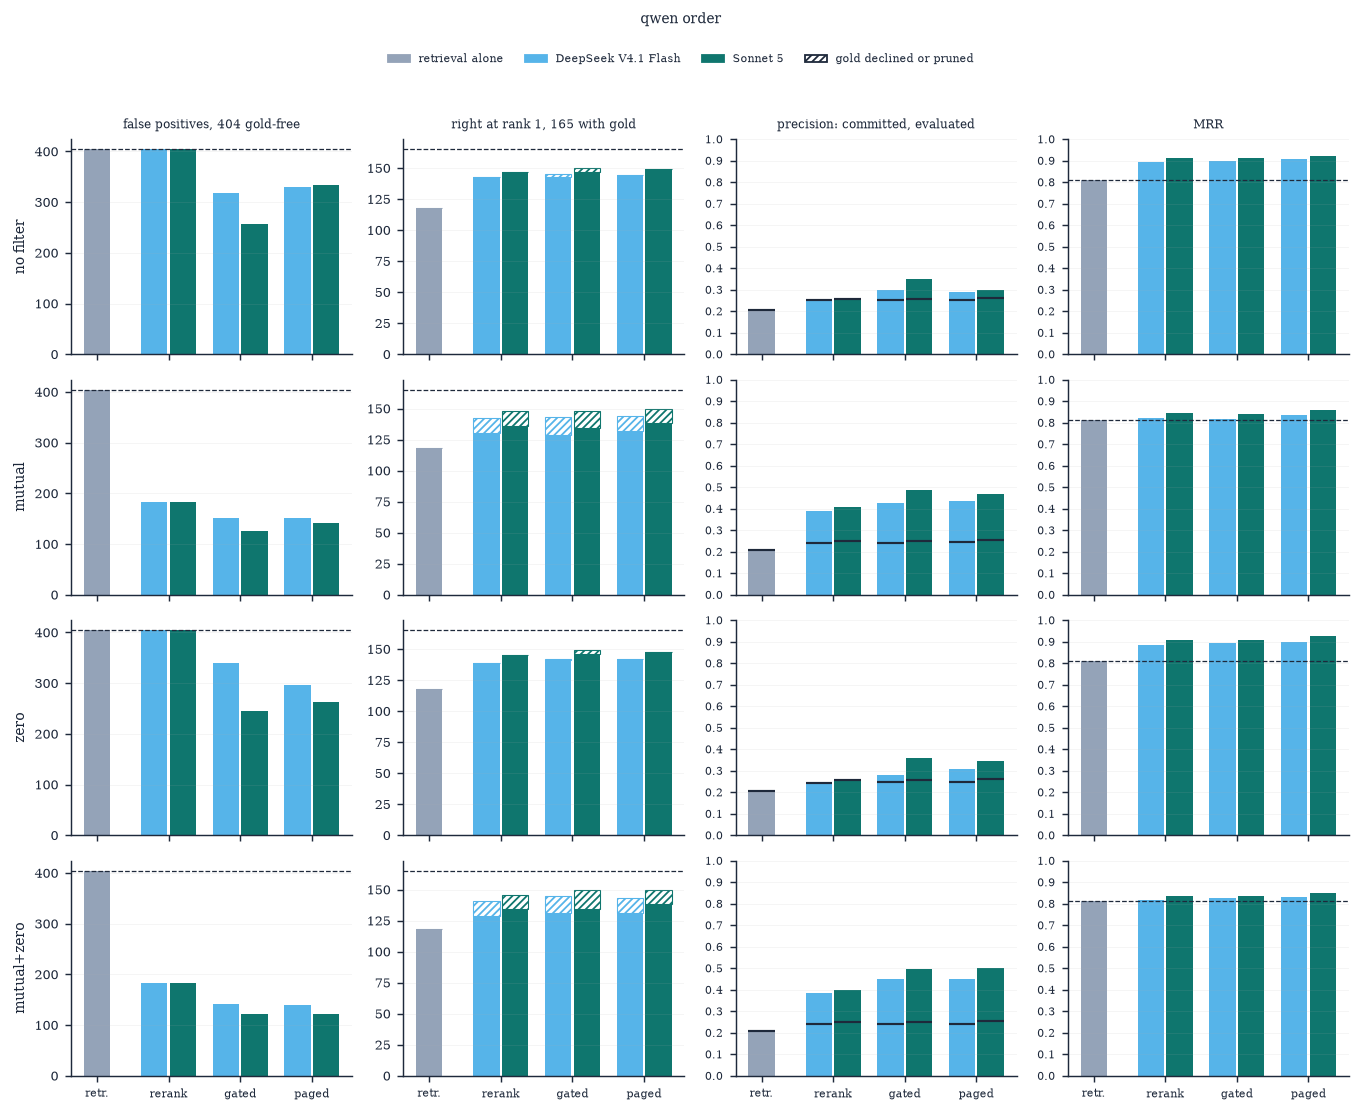

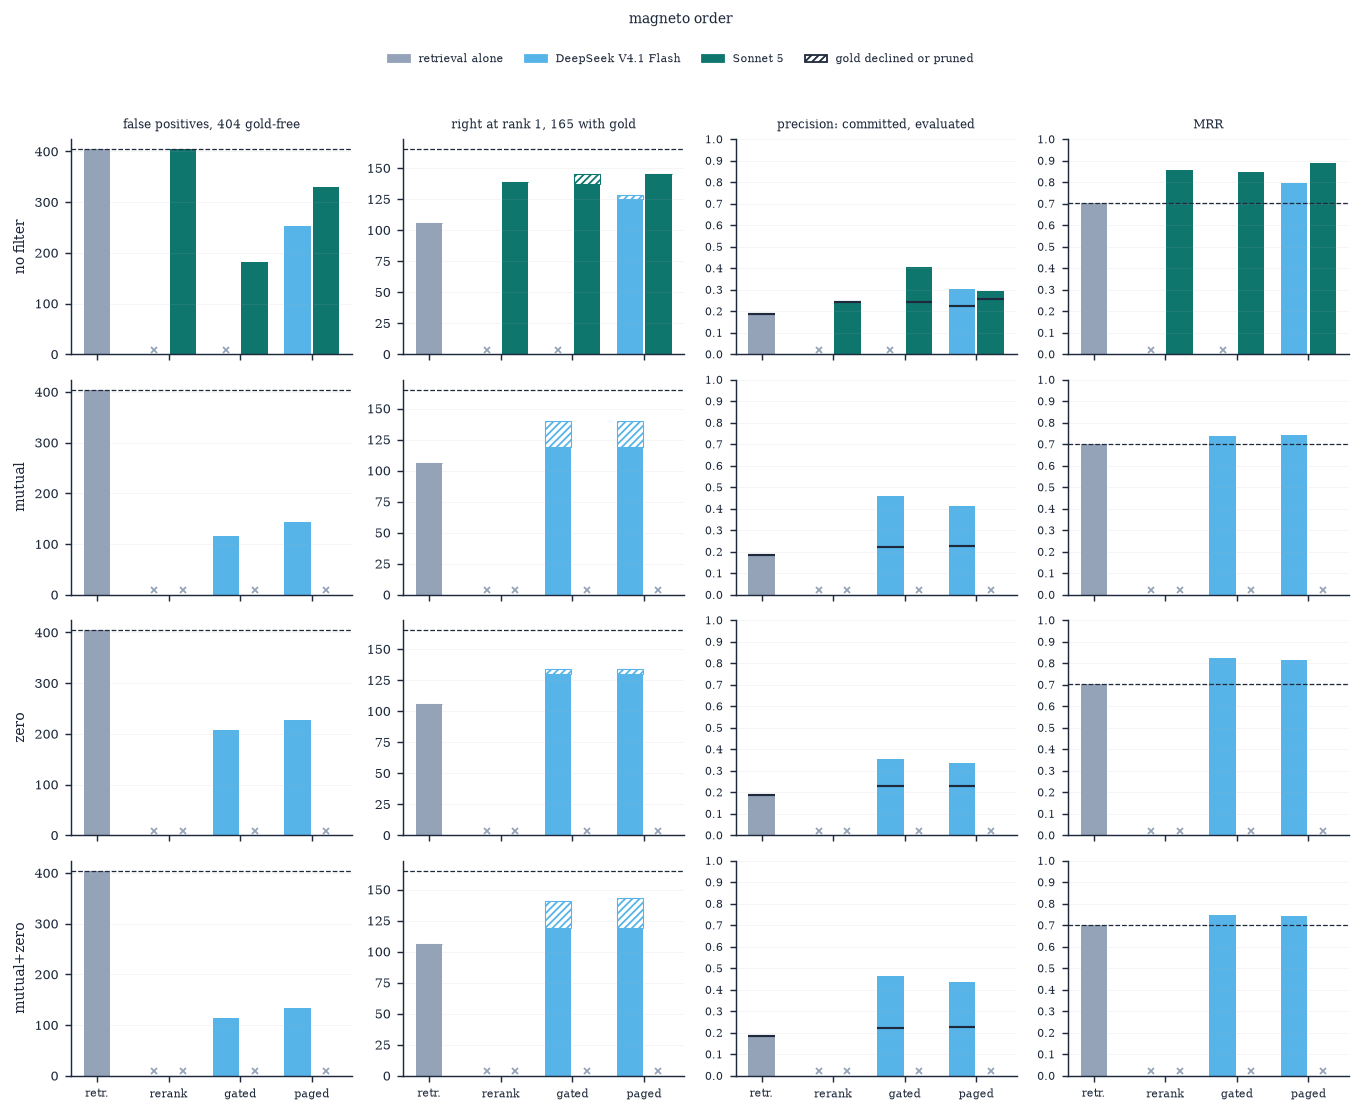

In [8]:
from matplotlib.ticker import MultipleLocator

GROUPS = ["retrieval", "rerank", "gated", "paged"]


def bars(ax, ret, f, value, stack=None, tick=None):
    w = 0.8 / len(MODELS)
    for g, arm in enumerate(GROUPS):
        slots = ([(g, None)] if arm == "retrieval" else
                 [(g - 0.4 + w * (k + 0.5), m) for k, m in enumerate(MODELS)])
        for x, m in slots:
            r = RET[ret] if m is None else row(ret, arm, m, f)
            colour = C_MUTE if m is None else MODELS[m][1]
            if r is None:
                ax.plot(x, 0.02, "x", ms=3, color=C_MUTE,
                        transform=ax.get_xaxis_transform())
                continue
            ax.bar(x, r[value], w * 0.92, color=colour)
            if stack:
                ax.bar(x, r[stack], w * 0.92, bottom=r[value], color="none",
                       edgecolor=colour, hatch="//////", lw=0.6)
            if tick:
                ax.hlines(r[tick], x - w * 0.46, x + w * 0.46, color=C_INK,
                          lw=1.2)
    ax.set_xticks(range(len(GROUPS)), ["retr.", "rerank", "gated", "paged"],
                  fontsize=6)
    ax.grid(axis="x", visible=False)


for ret in ORDERS:
    fig, axes = plt.subplots(len(FILTERS), 4, figsize=(W2*1.5, 2 * len(FILTERS)),
                             sharex=True, sharey="col")
    for i, f in enumerate(FILTERS):
        bars(axes[i, 0], ret, f, "fp_invented")
        axes[i, 0].axhline(N_FREE, color=C_INK, lw=0.7, ls="--")
        bars(axes[i, 1], ret, f, "tp", stack="fn_abstained")
        axes[i, 1].axhline(N_GOLD_COLS, color=C_INK, lw=0.7, ls="--")
        bars(axes[i, 2], ret, f, "precision_committed",
             tick="precision_evaluated")
        bars(axes[i, 3], ret, f, "mrr")
        axes[i, 3].axhline(RET[ret]["mrr"], color=C_INK, lw=0.7, ls="--")
        axes[i, 0].set_ylabel(f.replace("-", "+") or "no filter")

    # 0–1 columns (precision, MRR): fixed range, ticks every 0.1
    for ax in axes[:, 2:].flat:
        ax.set_ylim(0, 1)
        ax.yaxis.set_major_locator(MultipleLocator(0.1))
        ax.tick_params(axis="y", labelsize=6)

    for ax, title in zip(axes[0], [f"false positives, {N_FREE} gold-free",
                                   f"right at rank 1, {N_GOLD_COLS} with gold",
                                   "precision: committed, evaluated",
                                   "MRR"]):
        ax.set_title(title, fontsize=6.8)
    fig.legend(handles=[mpl.patches.Patch(color=C_MUTE, label="retrieval alone")]
               + model_handles()
               + [mpl.patches.Patch(facecolor="none", edgecolor=C_INK,
                                    hatch="//////", label="gold declined or pruned")],
               loc="upper center", ncol=7, bbox_to_anchor=(0.5, 1.03),
               fontsize=6)
    fig.suptitle(f"{ret} order", y=1.06, fontsize=8)
    fig.tight_layout()
    save(fig, f"fig_abstention_{ret}")
    plt.show()

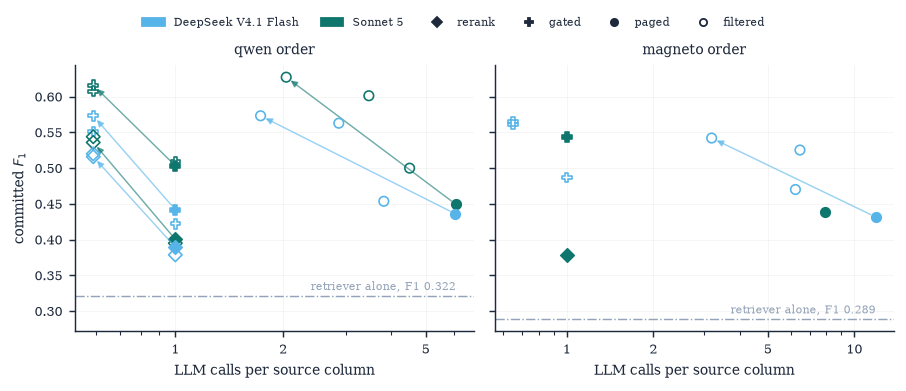

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(W2, 2.8), sharey=True)
for ax, ret in zip(axes, ORDERS):
    here = SCORED[SCORED["retriever"] == ret]
    for (arm, m), g in here.groupby(["kind", "model"]):
        g = g.set_index("filter")
        colour = MODELS[m][1]
        for f, r in g.iterrows():
            ax.scatter(r["calls_per_column"], r["f1_committed"], s=28, lw=0.9,
                       marker=MARKER[arm], edgecolors=colour, zorder=3,
                       color=colour if f == "" else "none")
        if {"", "mutual-zero"} <= set(g.index):
            xy = ["calls_per_column", "f1_committed"]
            ax.annotate("", xy=tuple(g.loc["mutual-zero", xy]),
                        xytext=tuple(g.loc["", xy]),
                        arrowprops=dict(arrowstyle="-|>", color=colour, lw=0.8,
                                        alpha=0.6, shrinkA=3, shrinkB=3))
    f1 = RET[ret]["f1_committed"]
    ax.axhline(f1, color=C_MUTE, lw=0.8, ls="-.")
    ax.text(here["calls_per_column"].max(), f1 + 0.008,
            f"retriever alone, F1 {f1:.3f}", fontsize=6, color=C_MUTE,
            ha="right")
    ax.set_xscale("log")
    ax.xaxis.set_major_locator(mpl.ticker.LogLocator(subs=(1, 2, 5)))
    ax.xaxis.set_major_formatter(mpl.ticker.FormatStrFormatter("%g"))
    ax.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())
    ax.set_xlabel("LLM calls per source column")
    ax.set_title(f"{ret} order")
axes[0].set_ylabel("committed $F_1$")
fig.legend(handles=model_handles()
           + [plt.Line2D([], [], marker=MARKER[a], ls="", color=C_INK,
                         label=a) for a in ARMS]
           + [plt.Line2D([], [], marker="o", ls="", mfc="none", mec=C_INK,
                         label="filtered")],
           loc="upper center", ncol=9, bbox_to_anchor=(0.5, 1.06), fontsize=6.2)
fig.tight_layout()
save(fig, "fig_cost_quality")
plt.show()

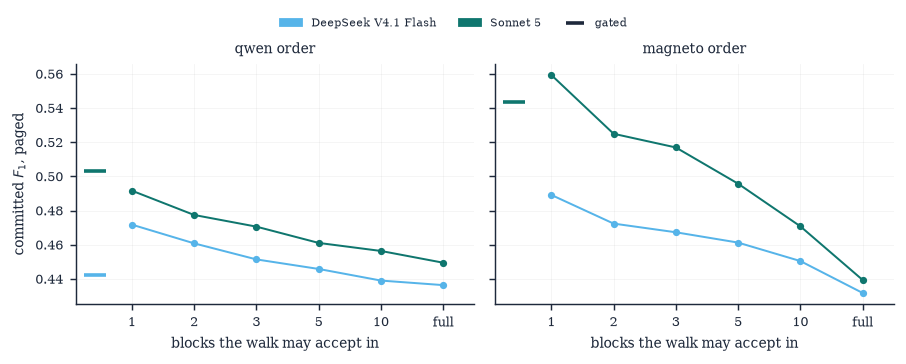

In [10]:
from evaluation import walk_rules

DEPTHS = [1, 2, 3, 5, 10, None]
fig, axes = plt.subplots(1, 2, figsize=(W2, 2.6), sharey=True)
for ax, ret in zip(axes, ORDERS):
    for m, (name, colour) in MODELS.items():
        if (ret, "paged", m, "") not in RUNS_OF:
            continue
        runs = RUNS_OF[(ret, "paged", m, "")]
        f1 = [walk_rules.score_replay(runs, PAIRS, results=RUNS, corpus=CORPUS,
                                      cap=d)["f1_committed"] for d in DEPTHS]
        ax.plot(range(len(DEPTHS)), f1, marker="o", ms=3, color=colour)
        gated = row(ret, "gated", m)
        if gated is not None:
            ax.plot(-0.6, gated["f1_committed"], marker="_", ms=12, mew=2,
                    color=colour, clip_on=False)
    ax.set_xticks(range(len(DEPTHS)), [str(d) if d else "full" for d in DEPTHS])
    ax.set_xlim(-0.9, len(DEPTHS) - 0.5)
    ax.set_xlabel("blocks the walk may accept in")
    ax.set_title(f"{ret} order")
axes[0].set_ylabel("committed $F_1$, paged")
fig.legend(handles=model_handles()
           + [plt.Line2D([], [], marker="_", ms=10, mew=2, ls="", color=C_INK,
                         label="gated"),
              ],
           loc="upper center", ncol=6, bbox_to_anchor=(0.5, 1.06), fontsize=6.2)
fig.tight_layout()
save(fig, "fig_depth")
plt.show()

In [11]:
def tagged(frame):
    return frame.assign(model=frame["arm"].str.split("__").str[0],
                        variant=frame["arm"].str.split("__").str[1:].str.join("__"))


INV = tagged(inventory.scan(RUNS, corpus=CORPUS, kinds=tuple(ARMS),
                            unparseable="stop"))
INV = INV[INV["pair"].isin(NAMES) & (INV["rep"] == 1)
          & INV["retriever"].isin(ORDERS) & INV["model"].isin(MODELS)
          & INV["variant"].isin(VARIANTS) & INV["prune"].isin(FILTERS)
          & ((INV["kind"] != "paged") & (INV["top_k"] == TOP_K)
             | (INV["kind"] == "paged") & (INV["window"] == WINDOW)
             & (INV["threshold"] == 0.50))]
OK = tagged(inventory.check(INV, verbose=False))

RUNS_OF, rows = {}, []
for ret in ORDERS:
    for arm in ARMS:
        for m in MODELS:
            for f in FILTERS:
                cell = OK[(OK["retriever"] == ret) & (OK["kind"] == arm)
                          & (OK["model"] == m) & (OK["prune"] == f)]
                for v in VARIANTS:
                    runs = cell[cell["variant"] == v]
                    if (set(runs["pair"]) == set(NAMES)
                            and runs["n_columns"].sum() == N_SRC):
                        RUNS_OF[(ret, arm, m, f)] = runs
                        s = report.score(runs, PAIRS, results=RUNS,
                                         corpus=CORPUS, kind=arm).iloc[0]
                        rows.append({**s, "retriever": ret, "kind": arm,
                                     "model": m, "filter": f})
                        break
                else:
                    print(f"not whole: {ret} / {arm} / {MODELS[m][0]} / "
                          f"{f or 'none'}")
SCORED = pd.DataFrame(rows)

RET, DEEP = {}, {}
for ret in ORDERS:
    order, gt = report.retrieval_rankings(PAIRS, results=RUNS, corpus=CORPUS,
                                          retriever=ret)
    RET[ret] = report.metrics(order, gt, {c: True for c in order})
    DEEP[ret] = {(s, t) for s, t, _ in matching.gold_beyond_k(order, gt, TOP_K)}
N_GOLD_COLS = RET["qwen"]["n_gold_columns"]
N_FREE = N_SRC - N_GOLD_COLS


def row(ret, arm, m, f=""):
    r = SCORED[(SCORED["retriever"] == ret) & (SCORED["kind"] == arm)
               & (SCORED["model"] == m) & (SCORED["filter"] == f)]
    return r.iloc[0] if len(r) else None

TypeError: scan() got an unexpected keyword argument 'unparseable'

In [ ]:
from matplotlib.ticker import MultipleLocator

GROUPS = ["retrieval", "rerank", "gated", "paged"]


def bars(ax, ret, f, value, stack=None, tick=None):
    w = 0.8 / len(MODELS)
    for g, arm in enumerate(GROUPS):
        slots = ([(g, None)] if arm == "retrieval" else
                 [(g - 0.4 + w * (k + 0.5), m) for k, m in enumerate(MODELS)])
        for x, m in slots:
            r = RET[ret] if m is None else row(ret, arm, m, f)
            colour = C_MUTE if m is None else MODELS[m][1]
            if r is None:
                ax.plot(x, 0.02, "x", ms=3, color=C_MUTE,
                        transform=ax.get_xaxis_transform())
                continue
            ax.bar(x, r[value], w * 0.92, color=colour)
            if stack:
                ax.bar(x, r[stack], w * 0.92, bottom=r[value], color="none",
                       edgecolor=colour, hatch="//////", lw=0.6)
            if tick:
                ax.hlines(r[tick], x - w * 0.46, x + w * 0.46, color=C_INK,
                          lw=1.2)
    ax.set_xticks(range(len(GROUPS)), ["retr.", "rerank", "gated", "paged"],
                  fontsize=6)
    ax.grid(axis="x", visible=False)


for ret in ORDERS:
    fig, axes = plt.subplots(len(FILTERS), 4, figsize=(W2*1.5, 2 * len(FILTERS)),
                             sharex=True, sharey="col")
    for i, f in enumerate(FILTERS):
        bars(axes[i, 0], ret, f, "fp_invented")
        axes[i, 0].axhline(N_FREE, color=C_INK, lw=0.7, ls="--")
        bars(axes[i, 1], ret, f, "tp", stack="fn_abstained")
        axes[i, 1].axhline(N_GOLD_COLS, color=C_INK, lw=0.7, ls="--")
        bars(axes[i, 2], ret, f, "precision_committed",
             tick="precision_evaluated")
        bars(axes[i, 3], ret, f, "mrr")
        axes[i, 3].axhline(RET[ret]["mrr"], color=C_INK, lw=0.7, ls="--")
        axes[i, 0].set_ylabel(f.replace("-", "+") or "no filter")

    # 0–1 columns (precision, MRR): fixed range, ticks every 0.1
    for ax in axes[:, 2:].flat:
        ax.set_ylim(0, 1)
        ax.yaxis.set_major_locator(MultipleLocator(0.1))
        ax.tick_params(axis="y", labelsize=6)

    for ax, title in zip(axes[0], [f"false positives, {N_FREE} gold-free",
                                   f"right at rank 1, {N_GOLD_COLS} with gold",
                                   "precision: committed, evaluated",
                                   "MRR"]):
        ax.set_title(title, fontsize=6.8)
    fig.legend(handles=[mpl.patches.Patch(color=C_MUTE, label="retrieval alone")]
               + model_handles()
               + [mpl.patches.Patch(facecolor="none", edgecolor=C_INK,
                                    hatch="//////", label="gold declined or pruned")],
               loc="upper center", ncol=7, bbox_to_anchor=(0.5, 1.03),
               fontsize=6)
    fig.suptitle(f"{ret} order", y=1.06, fontsize=8)
    fig.tight_layout()
    save(fig, f"fig_abstention_{ret}")
    plt.show()